# Towards the Assembly of the BINGO Radiotelescope
## Auxiliary Notebook

**Author**: Luciano Barosi

**E-Mail**: lbarosi@df.ufcg.edu.br

**Date**: 2026-08-14

## Initialization

In [1]:
"""Imports e setup do ambiente."""

from __future__ import annotations

import sys
from datetime import datetime
from pathlib import Path

import nest_asyncio
import numpy as np  # noqa: F401
import matplotlib.pyplot as plt
# ── Detecta raiz do projeto e adiciona src/ ao path ANTES dos imports do pacote ──
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
project_root = None
for p in candidates:
    if (p / "src" / "radioskysims").exists() and (p / "settings.toml").exists():
        project_root = p
        break

if project_root is None:
    msg = "Raiz do projeto não encontrada."
    raise RuntimeError(msg)

src_path = str((project_root / "src").resolve())
if src_path not in sys.path:
    sys.path.insert(0, src_path)

# ── Imports do projeto (após configurar sys.path) ──
from radioskysims.domain.beam.properties import BeamProperties
from radioskysims.domain.simulation.pointing import build_pointing_track
from radioskysims.infrastructure.beams.loaders.csv import CSVBeamLoader
from radioskysims.infrastructure.config.config_loader import (
    build_radiotelescope_from_settings,
)
from radioskysims.application.services.sim_orchestrator import SimOrchestrator
from radioskysims.domain.common import TimeRange

#-------Plotting utilities----------------
from plotting import jai
from plotting.colors import MEASUREMENT, MODEL
#-----------------------------------------
nest_asyncio.apply()

/home/lbarosi/RadioSkySim/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:628: UserWarning: <built-in function allocate_lock> is not a Python type (it may be an instance of an object), Pydantic will allow any object with no validation since we cannot even enforce that the input is an instance of the given type. To get rid of this error wrap the type with `pydantic.SkipValidation`.
  warn(


## Uirapuru

### Radiotelescope Instance

In [2]:
# ── 1) Carrega o radiotelescópio UIRAPURU a partir de settings.toml ──
rt = build_radiotelescope_from_settings("uirapuru")
ant = rt.antennas[0]
obs = rt.observer
print("Nome:", rt.name)
print("Antena:", ant.name)
print(
    f"Localização: lat={obs.lat.to_value('deg'):.5f}°, "
    f"lon={obs.lon.to_value('deg'):.5f}°, alt={obs.height.to_value('m'):.1f} m"
)
print("Time range da simulação:", obs.timeframe)

Nome: UIRAPURU Telescope
Antena: BINGO Horn
Localização: lat=-7.21164°, lon=-35.90813°, alt=530.0 m
Time range da simulação: start_jd=2460804.5 end_jd=2460805.5 resolution_sec=120.0


### Geolocation

In [3]:
import folium
from IPython.display import display

# ── 2) Mapa OSM com a localização do radiotelescópio ──
lat_deg = float(obs.lat.to_value("deg"))
lon_deg = float(obs.lon.to_value("deg"))
m = folium.Map(location=[lat_deg, lon_deg], zoom_start=9, tiles="OpenStreetMap")
folium.Marker(
    [lat_deg, lon_deg],
    popup=f"{rt.name}<br>({lat_deg:.4f}, {lon_deg:.4f})",
    tooltip=rt.name,
).add_to(m)
display(m)

### Beam

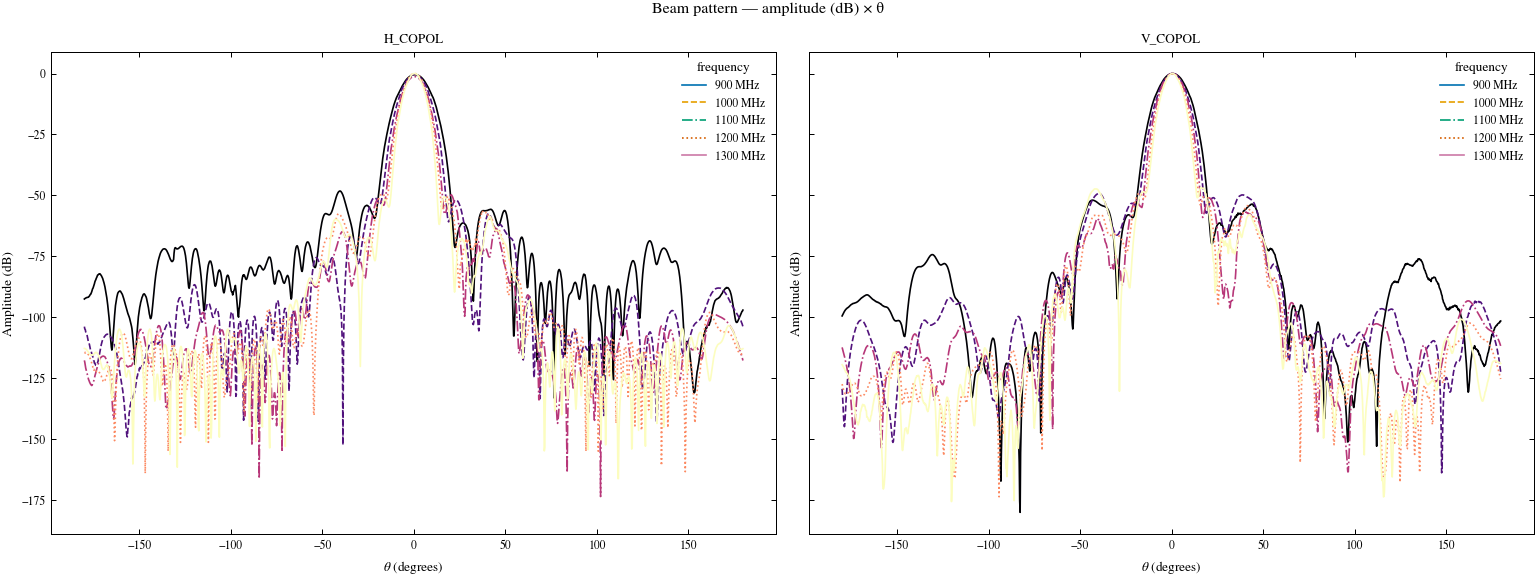

In [4]:
# ── Beam Pattern ──
beam = CSVBeamLoader(file=ant.beam.beam_pattern_file).load()
freqs_mhz = np.asarray(beam.dataset["frequency"].values, dtype=float)
 # dBi
freq_central = freqs_mhz.mean()
polarizations = ["H_COPOL", "V_COPOL"]
n_freqs = 4
freqs_selected = freqs_mhz[::freqs_mhz.size // n_freqs]
beam_selected = beam.dataset.sel(frequency=freqs_selected, polarization=polarizations)

props = BeamProperties.compute_properties(beam.dataset.sel(polarization=polarizations))
# -- Beam Pattern Visualization: Amplitude (dB) × θ — interface nativa do xarray
with jai.style():
    import matplotlib as mpl

    # Colormap perceptualmente uniforme (viridis) com normalização comum às
    # duas colunas — o mesmo vínculo frequência → cor em H_COPOL e V_COPOL.
    _norm = mpl.colors.Normalize(vmin=freqs_selected.min(), vmax=freqs_selected.max())
    _cmap = mpl.colormaps["magma"]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

    for ax, pol in zip(axes, polarizations):
        amp = beam_selected["amplitude"].sel(polarization=pol)  # dims (frequency, angle)
        amp_db = 20 * np.log10(amp.where(amp > 0))  # amplitude linear -> dB (mantém xarray)
        amp_db.plot.line(
            ax=ax,
            x="angle",
            hue="frequency",
        )
        # Aplica o colormap viridis (mesma normalização nas duas colunas)
        for _line, _f in zip(ax.lines, amp_db.frequency.values):
            _line.set_color(_cmap(_norm(float(_f))))

        ax.set_title(pol)
        ax.set(
            xlabel=r"$\theta$ (degrees)",
            ylabel=r"Amplitude (dB)",
        )
        #ax.grid(True, alpha=0.3)

        # Rótulos da legenda com a unidade em MHz
        _legend = ax.get_legend()
        if _legend is not None:
            for _t in _legend.get_texts():
                try:
                    _t.set_text(f"{float(_t.get_text()):g} MHz")
                except ValueError:
                    pass

    fig.suptitle("Beam pattern — amplitude (dB) × θ")
    plt.tight_layout()
    plt.show()

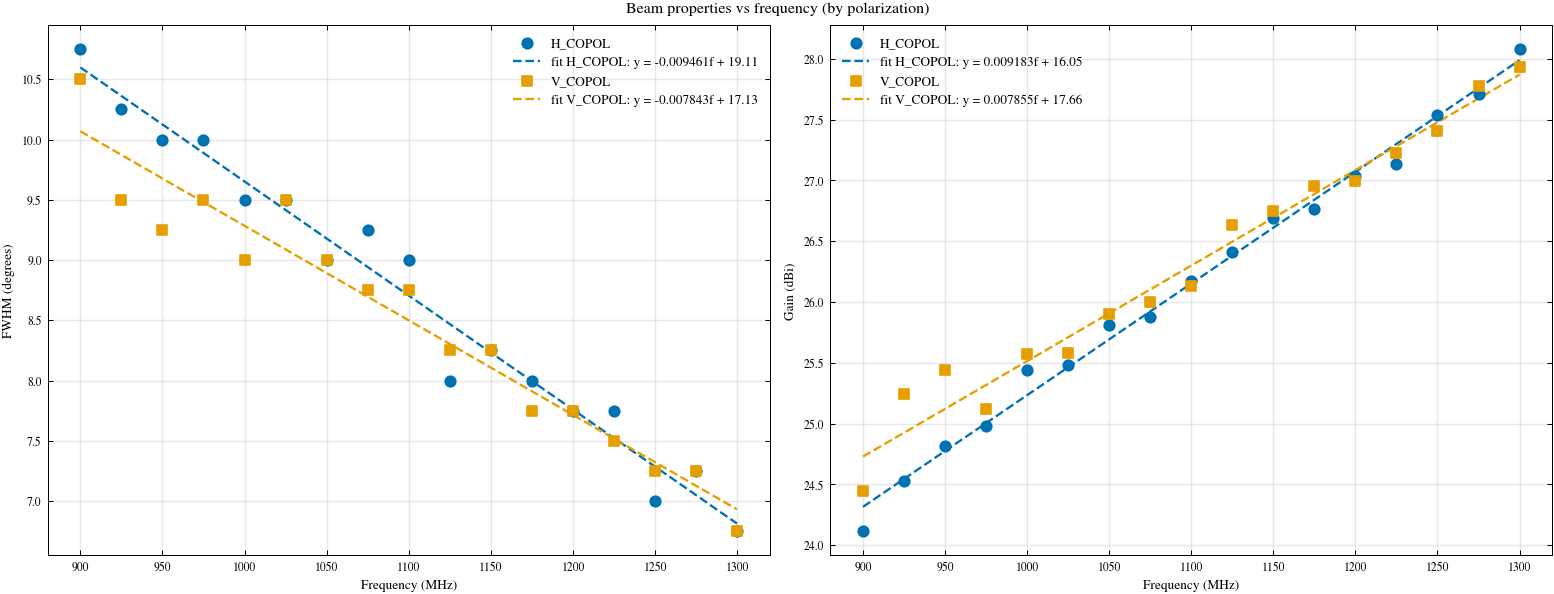

In [5]:
# ── Painel de propriedades do feixe vs frequência (por polarização) ──
# ax[0,0] → FWHM vs frequência | ax[0,1] → ganho vs frequência
# Cada polarização: marcador distinto, pontos sem linha de ligação e
# ajuste linear com os parâmetros na legenda.
with jai.style():
    # Marcadores e cores por polarização (paleta Okabe-Ito, compatível com o estilo JAI)
    _markers = {"H_COPOL": "o", "V_COPOL": "s"}
    _colors = {"H_COPOL": "#0072B2", "V_COPOL": "#E69F00"}  # azul / laranja

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

    for ax, (var, ylabel) in zip(
        axes, [("fwhm", "FWHM (degrees)"), ("directivity_db", "Gain (dBi)")]
    ):
        for pol in polarizations:
            y = np.asarray(props[var].sel(polarization=pol).values, dtype=float)
            _mask = np.isfinite(y)
            _x, _y = freqs_mhz[_mask], y[_mask]

            # Pontos de cada polarização — marcador distinto, sem linha de ligação
            ax.scatter(
                freqs_mhz, y,
                marker=_markers[pol],
                color=_colors[pol],
                s=40,
                label=pol,
                zorder=3,
            )

            # Ajuste linear y = a·f + b, com os parâmetros na legenda
            if _mask.sum() >= 2:
                _a, _b = np.polyfit(_x, _y, 1)
                ax.plot(
                    freqs_mhz, np.polyval([_a, _b], freqs_mhz),
                    linestyle="--",
                    color=_colors[pol],
                    lw=1.4,
                    label=f"fit {pol}: y = {_a:.4g}f + {_b:.4g}",
                    zorder=2,
                )

        ax.set(
            xlabel="Frequency (MHz)",
            ylabel=ylabel,
        )
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)

    fig.suptitle("Beam properties vs frequency (by polarization)")
    plt.show()

Pointing: 721 amostras | alt=65.0°, az=0.0°
RA: 0.29° .. 359.79° | DEC: 17.65° .. 17.93°


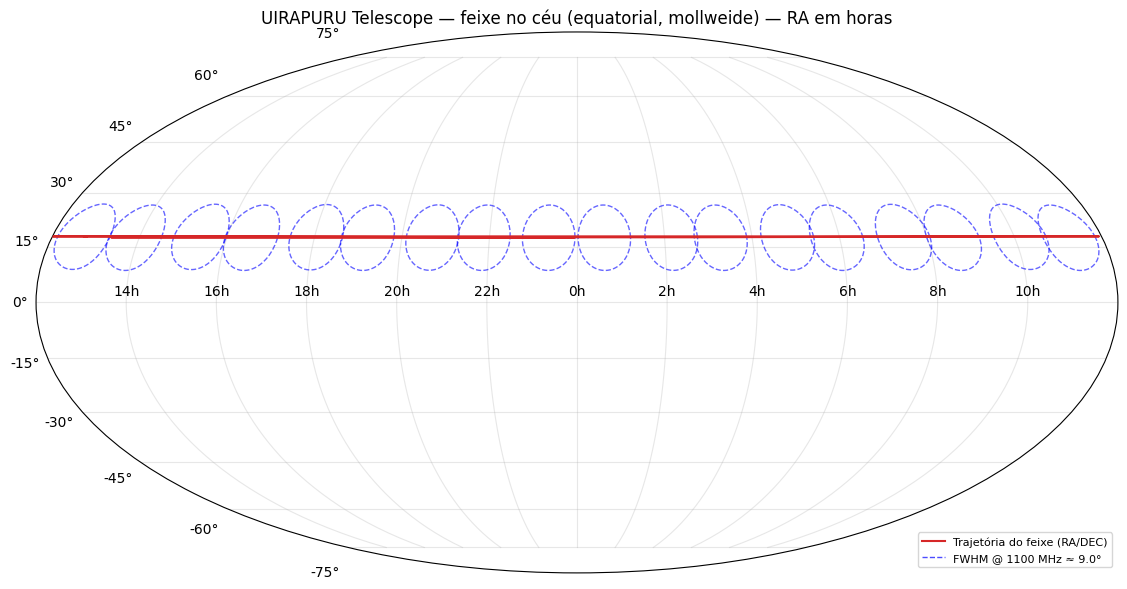

In [6]:
pt = build_pointing_track(ant, obs.timeframe, obs)
ra_deg = np.degrees(pt["ra"].values)
dec_deg = np.degrees(pt["dec"].values)
print(
    f"Pointing: {len(ra_deg)} amostras | "
    f"alt={ant.pointing.alt_deg}°, az={ant.pointing.az_deg}°"
)
print(
    f"RA: {ra_deg.min():.2f}° .. {ra_deg.max():.2f}° | "
    f"DEC: {dec_deg.min():.2f}° .. {dec_deg.max():.2f}°"
)

# ── 7) Trajetória do feixe no céu (mollweide): RA em hora-ângulo + banda do FWHM ──
# FWHM na frequência central (polarização H_COPOL) — índice mais próximo.
# (Evita `method="nearest"` do xarray, que falha com alvo escalar neste pandas.)
_f_idx = int(np.argmin(np.abs(props["fwhm"].frequency.values - freq_central)))
fwhm_fc = float(
    props["fwhm"].sel(polarization="H_COPOL").isel(frequency=_f_idx).values
)
r_rad = np.deg2rad(fwhm_fc)  # raio do footprint (meia-largura à meia potência)

# Amostragem densa do traçado (mais apontamentos)
ra_rad = np.deg2rad(ra_deg)
dec_rad = np.deg2rad(dec_deg)
n_dense = 400
_t = np.linspace(0, 1, n_dense)
ra_dense = np.interp(_t, np.linspace(0, 1, ra_rad.size), ra_rad)
dec_dense = np.interp(_t, np.linspace(0, 1, dec_rad.size), dec_rad)
ra_mw = ((ra_dense + np.pi) % (2 * np.pi)) - np.pi  # RA em [-pi, pi] para o mollweide

# Distância de arco acumulada ao longo do traçado
d_arc = np.concatenate(
    [[0.0], np.cumsum(np.hypot(
        np.diff(ra_dense) * np.cos(dec_dense[:-1]), np.diff(dec_dense)
    ))]
)
# Número fixo de contornos de FWHM ao longo do traçado (sem sobreposição)
n_contours = 18
k_pos = np.linspace(0.0, d_arc[-1], n_contours, endpoint=False)
ra_pos = np.interp(k_pos, d_arc, ra_dense)
dec_pos = np.interp(k_pos, d_arc, dec_dense)
ra_pos_mw = ((ra_pos + np.pi) % (2 * np.pi)) - np.pi

fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(111, projection="mollweide")

# Contorno do FWHM repetido (número reduzido) ao longo do traçado
_th = np.linspace(0, 2 * np.pi, 100)
for _ra_c, _dec_c in zip(ra_pos_mw, dec_pos):
    # pula contornos que cruzariam a borda RA = ±π (evita artefato no mollweide)
    if abs(abs(_ra_c) - np.pi) < r_rad:
        continue
    ax.plot(
        _ra_c + r_rad * np.cos(_th),
        _dec_c + r_rad * np.sin(_th),
        "b--", lw=1.0, alpha=0.6, zorder=2,
    )

# Trajetória do feixe (RA/DEC)
ax.plot(
    ra_mw, dec_dense,
    "-", color="tab:red", lw=1.5, zorder=3,
    label="Trajetória do feixe (RA/DEC)",
)

# Entrada única na legenda para o contorno do FWHM (proxy)
ax.plot(
    [], [], "b--", lw=1.0, alpha=0.7,
    label=f"FWHM @ {freq_central:.0f} MHz ≈ {fwhm_fc:.1f}°",
)

# Eixo RA em hora-ângulo: horas inteiras apenas nos meridianos (1 h = 15°)
# Observação: get_xticks() vem em radianos → converte para graus e depois horas.
ax.set_xticklabels([
    f"{int(round(np.degrees(t) / 15.0)) % 24}h" for t in ax.get_xticks()
])

ax.grid(True, alpha=0.3)
ax.legend(loc="lower right", fontsize=8)
ax.set_title(f"{rt.name} — feixe no céu (equatorial, mollweide) — RA em horas")
plt.tight_layout()
plt.show()

## Simulatiom

In [8]:
# ── Orquestrador BINGO ──
orch = SimOrchestrator.from_settings("uirapuru")


# ── Executa simulação multi-fonte (resultado LAZY — NUNCA materializar) ──
# O dataset simulation_result é sempre muito grande e não pode ser computado
# inteiro de uma vez. O orquestrador retorna arrays dask; events e to_hdf5/
# to_zarr consomem o dataset por chunks ao longo do tempo (memória limitada
# ao tamanho do chunk).
comp_result = orch.run(
    constellations=["GPS", "GALILEO", "GLONASS", "BEIDOU"],
    include_local_sources=True,  # Sol
    # include_radio_sources=True,  # NVSS (se houver dados)
    use_processor=True,
)


ds_orch = comp_result.simulation_result.dataset

{'event': 'spacetrack_update_empty_result', 'requested_count': 2, 'norad_ids': [67162, 68791], 'detail': 'SpaceTrack retornou 0 TLEs. Pode significar que: (1) todos os NORAD IDs já foram consultados hoje (cache diário); (2) as credenciais são inválidas; (3) não há TLEs disponíveis para os NORAD IDs solicitados no período.'}
{'event': 'spacetrack_update_empty_result', 'requested_count': 2, 'norad_ids': [67162, 68791], 'detail': 'SpaceTrack retornou 0 TLEs. Pode significar que: (1) todos os NORAD IDs já foram consultados hoje (cache diário); (2) as credenciais são inválidas; (3) não há TLEs disponíveis para os NORAD IDs solicitados no período.'}


In [9]:
comp_result.summary

<bound method SimulationOrchestratorResult.summary of ════════════════════════════════════════════════════════════════════════
  RADIOSKYSIM — RESUMO DA SIMULAÇÃO
════════════════════════════════════════════════════════════════════════

┌─ OBSERVER ──────────────────────────────────────────────
  Nome                    : uirapuru
  Localização (lat/lon)    : -7.21 / -35.91  (height 530 m)
  Frequency Range (MHz)    : 1000 → 1250  (n_channels=5000)
  Central Frequency (MHz) : 1125
  Antenna                 : BINGO Horn
    Pointing (Alt/Az)      : 65.00° / 0.00°
    Polarizations         : ['H_COPOL']
    Beam FWHM (deg)       : min 6.75 / med — / max 14.25
    Directivity (dBi)     : min 22.8147 / med — / max 34.1659

┌─ SIMULATION ─────────────────────────────────────────────
  Timerange (UTC)         : 2025-05-09T00:00:00.000 → 2025-05-10T00:00:00.000  (step 120 s)
  Sky ─ Localsources:
    - Sun
        Flux@fc (Jy)          : —
        Antenna Temp (K)      : —
        flux datafi

In [10]:
outdir = Path(project_root) / "data/TOD/"
outdir.mkdir(exist_ok=True)

# Nome com timestamp evita conflito/trava ao reexecutar (arquivo já existente)
ts = datetime.now().strftime("%Y%m%dT%H%M%S")

# HDF5 (NetCDF) — save_result (composto) salva dataset + sidecar JSON e
# atualiza os flags saved/filepath no config do SimulationOrchestratorResult.
# Sem chunk_s, o tamanho do chunk é derivado de target_mb (auto).
p_nc = outdir / f"tod_result_{ts}.nc"
comp_result.save_result(str(p_nc))

'/home/lbarosi/RadioSkySim/data/TOD/tod_result_20260817T095951.nc.json'

In [11]:
# ── Events: dataset de trânsitos calculados (por chunks, dataset pequeno) ──
# events percorre o dataset lazy em chunks ao longo do tempo, selecionando
# angle_boresight: cada intervalo contíguo no feixe vira um trânsito (fonte,
# início/fim, duração, T_antenna). O dataset de transits é pequeno e o
# dataset completo NUNCA é materializado.
events = comp_result.events

# ── Repositório de simulações (persistência do resumo no banco) ──
repo = orch.simulation_repository
sim_id = orch.save_result(comp_result, registered=True)

# O repositório atualiza o config do resultado com o que foi persistido:
comp = comp_result.config["computation"]
print(f"💾 Registro id={sim_id}")
print(f"   saved={comp.get('saved')} | registered={comp.get('registered')}")
print(f"   filepath={comp.get('filepath')}")

# ── Encerra o scheduler distribuído (se use_processor=True) ──
# Após persistir, libera workers/memória/dashboard do dask "distributed".
orch.shutdown()

💾 Registro id=11
   saved=True | registered=True
   filepath=/home/lbarosi/RadioSkySim/data/TOD/tod_result_20260817T095951.nc


In [ ]:
orch = SimOrchestrator.from_settings("uirapuru")


comp_result_nvss = orch.run(
    #include_local_sources=True,  # Sol
    include_radio_sources=True,  # NVSS (se houver dados)
    use_processor=True,
)


ds_orch_nvss = comp_result_nvss.simulation_result.dataset

outdir = Path(project_root) / "data/TOD/"
outdir.mkdir(exist_ok=True)


ts = datetime.now().strftime("%Y%m%dT%H%M%S")
p_nc = outdir / f"tod_result_nvss_{ts}.nc"
comp_result_nvss.save_result(str(p_nc))

events_nvss = comp_result_nvss.events

# ── Repositório de simulações (persistência do resumo no banco) ──
repo = orch.simulation_repository
sim_id = orch.save_result(comp_result_nvss, registered=True)

# O repositório atualiza o config do resultado com o que foi persistido:
comp = comp_result_nvss.config["computation"]
print(f"💾 Registro id={sim_id}")
print(f"   saved={comp.get('saved')} | registered={comp.get('registered')}")
print(f"   filepath={comp.get('filepath')}")

orch.shutdown()

{'event': 'spacetrack_update_empty_result', 'requested_count': 2, 'norad_ids': [67162, 68791], 'detail': 'SpaceTrack retornou 0 TLEs. Pode significar que: (1) todos os NORAD IDs já foram consultados hoje (cache diário); (2) as credenciais são inválidas; (3) não há TLEs disponíveis para os NORAD IDs solicitados no período.'}
{'event': 'spacetrack_update_empty_result', 'requested_count': 148, 'norad_ids': [26407, 27663, 28190, 28474, 28874, 29486, 29601, 32260, 32275, 32276, 32384, 32393, 32395, 32711, 35752, 36111, 36112, 36402, 36585, 36828, 37210, 37256, 37384, 37605, 37763, 37846, 37847, 37867, 37868, 37869, 38091, 38250, 38251, 38775, 38779, 38833, 38857, 38953, 39155, 39166, 39533, 39620, 39741, 40001, 40105, 40128, 40129, 40294, 40315, 40534, 40544, 40545, 40549, 40730, 40748, 40749, 40890, 40938, 41019, 41028, 41174, 41175, 41328, 41330, 41434, 41549, 41550, 41586, 41859, 41860, 41861, 41862, 42939, 43001, 43002, 43055, 43056, 43057, 43058, 43107, 43108, 43207, 43208, 43245, 4324

In [ ]:
# TODO 02 — Trânsitos no feixe, órbitas no céu e waterfall
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from IPython.display import display

from radioskysims.domain.simulation.pointing import build_pointing_track
from radioskysims.infrastructure.config.config_loader import (
    build_radiotelescope_from_settings,
)

# ── 1) Tabela de intervalos de trânsito de satélites no feixe ──
transits = events.transits
transits_nvss = events_nvss.transits
if transits is not None and transits.sizes["transit"]:
    tr_df = (
        transits.to_dataframe()
        .reset_index()
        .sort_values("start_time")
        .reset_index(drop=True)
    )
    tr_df["start_utc"] = pd.to_datetime(tr_df["start_time"]).dt.strftime("%Y-%m-%d %H:%M:%S")
    tr_df["end_utc"] = pd.to_datetime(tr_df["end_time"]).dt.strftime("%Y-%m-%d %H:%M:%S")
    tr_df["duration_min"] = (tr_df["duration_s"] / 60.0).round(1)
    tr_df["t_antenna_mean"] = tr_df["t_antenna_mean"].round(3)
    tr_df["t_antenna_max"] = tr_df["t_antenna_max"].round(3)
    tr_df["angle_boresight_min_deg"] = tr_df["angle_boresight_min_deg"].round(2)

else:
    print("Nenhum trânsito detectado no feixe.")
    
if transits_nvss is not None and transits_nvss.sizes["transit"]:
    tr_nvss_df = (
        transits.to_dataframe()
        .reset_index()
        .sort_values("start_time")
        .reset_index(drop=True)
    )
    tr_nvss_df["start_utc"] = pd.to_datetime(tr_nvss_df["start_time"]).dt.strftime("%Y-%m-%d %H:%M:%S")
    tr_nvss_df["end_utc"] = pd.to_datetime(tr_nvss_df["end_time"]).dt.strftime("%Y-%m-%d %H:%M:%S")
    tr_nvss_df["duration_min"] = (tr_nvss_df["duration_s"] / 60.0).round(1)
    tr_nvss_df["t_antenna_mean"] = tr_nvss_df["t_antenna_mean"].round(3)
    tr_nvss_df["t_antenna_max"] = tr_nvss_df["t_antenna_max"].round(3)
    tr_nvss_df["angle_boresight_min_deg"] = tr_nvss_df["angle_boresight_min_deg"].round(2)
else:
    print("Nenhum trânsito detectado no feixe.")
    
tr_df = pd.concat([tr_df, tr_nvss_df], ignore_index=True).sort_values("start_time").drop_duplicates(subset=["source", "start_time"]).reset_index(drop=True)
display(
    tr_df[
        [
            "source", "source_type", "pointing",
            "start_utc", "end_utc", "duration_min",
            "t_antenna_mean", "t_antenna_max", "angle_boresight_min_deg",
        ]
    ]
)
print(
    f"Total: {len(tr_df)} trânsitos | "
    f"fontes no feixe: {', '.join(str(x) for x in events.objects_in_beam)}"
)

,source,source_type,pointing,start_utc,end_utc,duration_min,t_antenna_mean,t_antenna_max,angle_boresight_min_deg
0,GPS BIIF-3 (PRN 24),satellite,0,2025-05-09 00:05:00,2025-05-09 01:30:00,85.0,0.006,2.763,0.27
1,BEIDOU-3 M17 (C36),satellite,0,2025-05-09 00:05:00,2025-05-09 01:30:00,85.0,0.004,0.570,0.28
2,COSMOS 2434 (721),satellite,0,2025-05-09 00:55:00,2025-05-09 02:20:00,85.0,7.179,3899.521,0.10
3,BEIDOU-3 M4 (C22),satellite,0,2025-05-09 01:00:00,2025-05-09 01:00:00,0.0,0.001,0.111,0.44
4,GPS BIII-3 (PRN 23),satellite,0,2025-05-09 01:30:00,2025-05-09 02:35:00,65.0,0.002,0.794,0.33
...,...,...,...,...,...,...,...,...,...
76,GSAT0203 (GALILEO 7),satellite,0,2025-05-09 21:00:00,2025-05-09 22:05:00,65.0,41.766,2053.793,0.05
77,GSAT0225 (GALILEO 29),satellite,0,2025-05-09 21:05:00,2025-05-09 23:00:00,115.0,0.004,0.335,0.33
78,GSAT0222 (GALILEO 26),satellite,0,2025-05-09 22:20:00,2025-05-09 23:10:00,50.0,0.003,0.208,0.41
79,GPS BIIRM-8 (PRN 05),satellite,0,2025-05-09 22:30:00,2025-05-09 23:45:00,75.0,0.004,0.957,0.33


Total: 81 trânsitos | fontes no feixe: BEIDOU-2 M3 (C11), BEIDOU-2 M4 (C12), BEIDOU-3 M10 (C30), BEIDOU-3 M11 (C25), BEIDOU-3 M13 (C32), BEIDOU-3 M15 (C34), BEIDOU-3 M17 (C36), BEIDOU-3 M19 (C41), BEIDOU-3 M21 (C43), BEIDOU-3 M22 (C44), BEIDOU-3 M23 (C45), BEIDOU-3 M28 (C50), BEIDOU-3 M3 (C21), BEIDOU-3 M4 (C22), BEIDOU-3 M6 (C24), BEIDOU-3 M7 (C27), BEIDOU-3 M8 (C28), BEIDOU-3S M2S (C58), COSMOS 2432 (719), COSMOS 2433 (720), COSMOS 2434 (721), COSMOS 2436 (723), COSMOS 2456 (730), COSMOS 2460 (732), COSMOS 2475 (743), COSMOS 2476 (744), COSMOS 2477 (745), COSMOS 2501 (702K), COSMOS 2522 (752), COSMOS 2544 (759), COSMOS 2545 (760), COSMOS 2559 (707K), COSMOS 2569 (703K), COSMOS 2596 (708K), GPS BIIF-1 (PRN 25), GPS BIIF-12 (PRN 32), GPS BIIF-3 (PRN 24), GPS BIIF-4 (PRN 27), GPS BIIF-6 (PRN 06), GPS BIIF-7 (PRN 09), GPS BIIF-8 (PRN 03), GPS BIII-3 (PRN 23), GPS BIII-5 (PRN 11), GPS BIII-6 (PRN 28), GPS BIII-7 (PRN 01), GPS BIIR-11 (PRN 19), GPS BIIR-13 (PRN 02), GPS BIIRM-1 (PRN 17), G

: 

: 

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
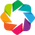

BokehModel(combine_events=True, render_bundle={'docs_json': {'4c818a72-2b8e-4af3-be64-873155494a58': {'version…

: 

: 

In [ ]:
# ── 3) Waterfall TOD — satélites ──
from radioskysims.visualization import waterfall_plot

waterfall_plot(
    ds_orch,
    #source_type="satellite",
    pointing=0,
    use_datashader=True,
    title="Waterfall TOD",
    cmap="inferno",
    ylim=(990, 1260),
    time_mode="local"
)

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
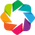

BokehModel(combine_events=True, render_bundle={'docs_json': {'2c021a80-25f0-40f4-b343-ce87a8b72ccc': {'version…

: 

: 

In [ ]:
time_range_sun = TimeRange.from_iso("2025-05-09T12:00:00", "2025-05-09T17:00:00", resolution=300)

waterfall_plot(
    ds_orch,
    source_type="localsource",
    pointing=0,
    use_datashader=True,
    title="Waterfall TOD",
    cmap="inferno",
    ylim=(990, 1260),
    time_mode="local",
    time_range=time_range_sun
    
)

In [ ]:
ds_orch_nvss.source_type

<xarray.DataArray 'source_type' (source: 64)> Size: 2kB
array(['satellite', 'satellite', 'satellite', 'satellite', 'satellite',
       'satellite', 'satellite', 'satellite', 'satellite', 'satellite',
       'satellite', 'satellite', 'satellite', 'satellite', 'satellite',
       'satellite', 'satellite', 'satellite', 'satellite', 'satellite',
       'satellite', 'satellite', 'satellite', 'satellite', 'satellite',
       'satellite', 'satellite', 'satellite', 'satellite', 'satellite',
       'satellite', 'satellite', 'satellite', 'satellite', 'satellite',
       'satellite', 'satellite', 'satellite', 'satellite', 'satellite',
       'satellite', 'satellite', 'satellite', 'satellite', 'satellite',
       'satellite', 'satellite', 'satellite', 'satellite', 'satellite',
       'satellite', 'satellite', 'satellite', 'satellite', 'satellite',
       'satellite', 'satellite', 'satellite', 'satellite', 'satellite',
       'satellite', 'satellite', 'satellite', 'satellite'], dtype='<U9')
Coordinates:
    source_type  (source) <U9 2kB 'satellite' 'satellite' ... 'satellite'
  * source       (source) <U21 5kB 'GPS BIIR-11 (PRN 19)' ... 'COSMOS 2596 (7...

: 

: 

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
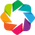

ValueError: Nenhuma fonte dos tipos ['radiosource'] encontrada.

: 

: 

In [ ]:
ds_orch_nvss = comp_result_nvss.simulation_result.dataset

waterfall_plot(
    ds_orch_nvss,
    source_type="radiosource",
    pointing=0,
    use_datashader=True,
    title="Waterfall TOD",
    cmap="inferno",
    ylim=(990, 1260),
    time_mode="local",
    
)

: 

: 